# Phase 2 - EDA Analysis

This notebook performs exploratory data analysis (EDA) on the merged review-level dataset for the fake review detection project.

## Goals
- Understand the overall dataset structure
- Check data quality
- Compare fake vs genuine reviews
- Identify useful patterns for later modeling
- Generate figures for the report and slides

# 1. Import Libraries

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# create output folder
os.makedirs("outputs", exist_ok=True)

# 2. Load Dataset

In [4]:
df = pd.read_csv("../phase1/final_dataset.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (100000, 60)


,review_id,product_id,user_id,review_date,year,month,star_rating,sentiment,verified_purchase,is_fake_review,review_length_words,has_title,title_word_count,num_images_attached,helpful_votes,total_votes,helpful_ratio,days_since_purchase,reviewer_review_count,is_top_reviewer,is_early_review,exclamation_marks,all_caps_ratio,readability_score,category,price_usd,price_tier,brand_tier,sent_star_rating,sentiment_label,sentiment_score,quality_aspect,shipping_aspect,value_aspect,service_aspect,emotion,sent_is_fake_review,fake_confidence_score,is_sarcastic,subjectivity_score,polarity_score,seller_id,true_quality,is_prime,product_num_images,bullet_points,has_video,days_on_platform,product_total_reviews,product_avg_rating,n_products,avg_product_rating,seller_total_reviews,avg_star,fake_rate,verified_rate,years_on_platform,ships_internationally,avg_shipping_days,return_rate_pct
0,R00000001,P000873,U009862,2024-01-21,2024,1,5,positive,1,0,34,1,3,0,18,19,0.947,7,38,1,0,1,0.001,49.2,Automotive,91.13,mid,mid,5,positive,1.000,positive,positive,positive,neutral,delight,0,0.206,0,0.507,0.796,S0173,4.58,1,1,7,0,1699,53,3.93,8,3.24,129,3.57,0.0078,0.721,4,1,5.4,4.3
1,R00000002,P002733,U037196,2024-10-07,2024,10,4,positive,1,0,62,1,11,0,1,2,0.500,7,6,0,0,0,0.073,81.4,Books,14.12,budget,premium,4,positive,0.701,neutral,neutral,positive,positive,satisfaction,0,0.054,0,0.887,0.441,S0122,4.32,0,2,5,0,1655,36,3.96,15,3.31,319,3.75,0.0627,0.727,4,0,3.4,11.4
2,R00000003,P002589,U034741,2024-03-01,2024,3,5,positive,1,0,104,0,0,0,2,2,1.000,21,38,1,0,1,0.015,68.2,Home & Kitchen,91.03,mid,budget,5,positive,1.000,positive,positive,positive,positive,satisfaction,0,0.329,0,0.837,0.836,S0453,4.31,0,7,5,0,451,17,4.08,6,3.17,120,3.50,0.0417,0.750,5,0,2.3,8.7
3,R00000004,P001303,U037748,2024-03-23,2024,3,5,positive,1,0,92,1,10,0,32,41,0.780,30,42,1,0,2,0.078,97.5,Beauty,46.51,low,mid,5,positive,0.960,positive,positive,positive,positive,satisfaction,0,0.418,0,0.799,0.891,S0108,4.25,0,7,6,0,1632,43,3.62,14,3.14,275,3.69,0.0436,0.727,5,1,5.2,3.8
4,R00000005,P002439,U035906,2022-01-28,2022,1,3,neutral,1,1,110,1,6,5,8,12,0.667,15,44,1,0,6,0.323,41.4,Home & Kitchen,49.67,low,premium,3,neutral,0.031,neutral,neutral,negative,positive,neutral,1,0.754,0,0.978,0.116,S0382,4.22,0,1,6,1,1318,298,3.84,15,3.03,288,3.38,0.0729,0.760,7,0,3.5,12.0


# 3. Basic structure check

In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['review_id', 'product_id', 'user_id', 'review_date', 'year', 'month', 'star_rating', 'sentiment', 'verified_purchase', 'is_fake_review', 'review_length_words', 'has_title', 'title_word_count', 'num_images_attached', 'helpful_votes', 'total_votes', 'helpful_ratio', 'days_since_purchase', 'reviewer_review_count', 'is_top_reviewer', 'is_early_review', 'exclamation_marks', 'all_caps_ratio', 'readability_score', 'category', 'price_usd', 'price_tier', 'brand_tier', 'sent_star_rating', 'sentiment_label', 'sentiment_score', 'quality_aspect', 'shipping_aspect', 'value_aspect', 'service_aspect', 'emotion', 'sent_is_fake_review', 'fake_confidence_score', 'is_sarcastic', 'subjectivity_score', 'polarity_score', 'seller_id', 'true_quality', 'is_prime', 'product_num_images', 'bullet_points', 'has_video', 'days_on_platform', 'product_total_reviews', 'product_avg_rating', 'n_products', 'avg_product_rating', 'seller_total_reviews', 'avg_star', 'fake_rate', 'verified_rate', 'years_on_platf

# 4. Missing values check

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_ratio_pct": (df.isnull().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

missing_summary.head(20)

,missing_count,missing_ratio_pct
review_id,0,0.0
product_id,0,0.0
user_id,0,0.0
review_date,0,0.0
year,0,0.0
month,0,0.0
star_rating,0,0.0
sentiment,0,0.0
verified_purchase,0,0.0
is_fake_review,0,0.0


# 5. Duplicate and label consistency check

In [7]:
print("Duplicated review_id count:", df["review_id"].duplicated().sum())

if "sent_is_fake_review" in df.columns:
    agreement = (df["is_fake_review"] == df["sent_is_fake_review"]).mean()
    print("Label agreement rate between is_fake_review and sent_is_fake_review:", agreement)
else:
    print("sent_is_fake_review column not found.")

Duplicated review_id count: 0
Label agreement rate between is_fake_review and sent_is_fake_review: 1.0


# 6. Target distribution

In [8]:
target_counts = df["is_fake_review"].value_counts().sort_index()
target_ratio = (df["is_fake_review"].value_counts(normalize=True).sort_index() * 100).round(2)

print("Target counts:")
print(target_counts)
print("\nTarget ratio (%):")
print(target_ratio)

Target counts:
is_fake_review
0    94100
1     5900
Name: count, dtype: int64

Target ratio (%):
is_fake_review
0    94.1
1     5.9
Name: proportion, dtype: float64


# 7. Plot 1: Fake vs Genuine distribution

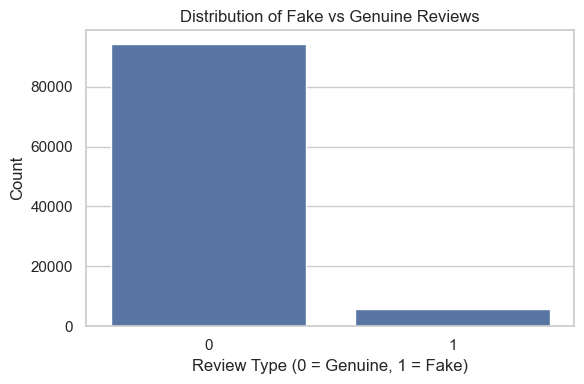

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="is_fake_review")
plt.title("Distribution of Fake vs Genuine Reviews")
plt.xlabel("Review Type (0 = Genuine, 1 = Fake)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("outputs/fake_vs_genuine_distribution.png", dpi=300)
plt.show()

# 8. Helper function for boxplots

In [10]:
def plot_box_by_target(data, feature, target="is_fake_review", save=True):
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=data, x=target, y=feature)
    plt.title(f"{feature} by Review Type")
    plt.xlabel("Review Type (0 = Genuine, 1 = Fake)")
    plt.ylabel(feature)
    plt.tight_layout()
    if save:
        plt.savefig(f"outputs/{feature}_boxplot.png", dpi=300)
    plt.show()

# 9. Plot 2: Review length

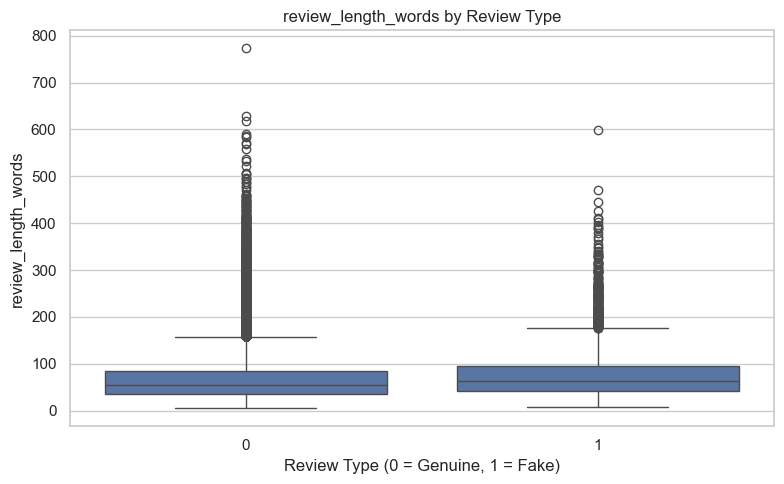

In [11]:
plot_box_by_target(df, "review_length_words")

# 10. Plot 3: Helpful ratio

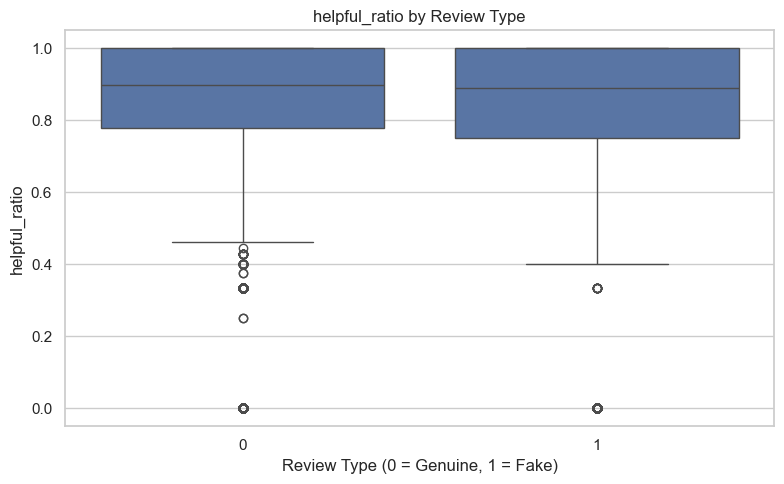

In [12]:
plot_box_by_target(df, "helpful_ratio")

# 11. Plot 4: Sentiment score (raw vs clean version)

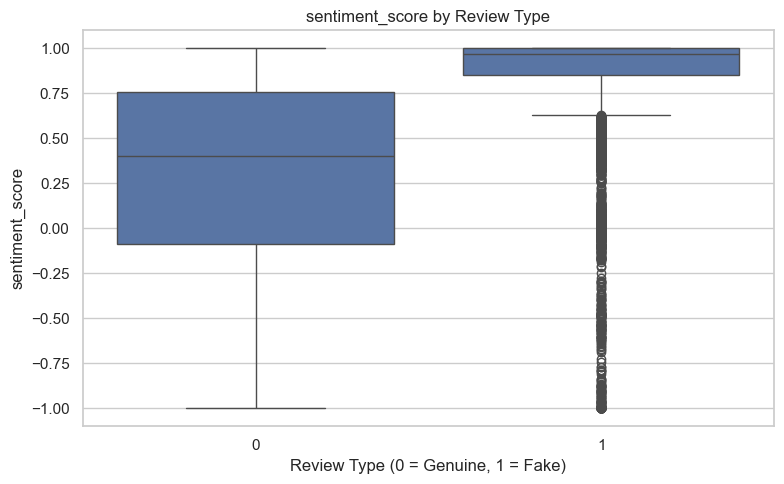

In [13]:
plot_box_by_target(df, "sentiment_score")

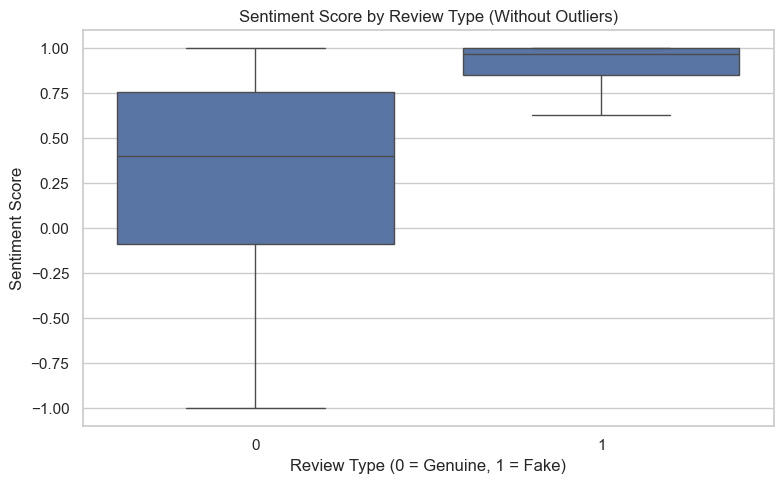

In [14]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='is_fake_review', y='sentiment_score', showfliers=False)

plt.title("Sentiment Score by Review Type (Without Outliers)")
plt.xlabel("Review Type (0 = Genuine, 1 = Fake)")
plt.ylabel("Sentiment Score")

plt.tight_layout()
plt.savefig("outputs/sentiment_score_boxplot_clean.png", dpi=300)
plt.show()

# 12. Plot 5: Polarity score (raw vs clean version)

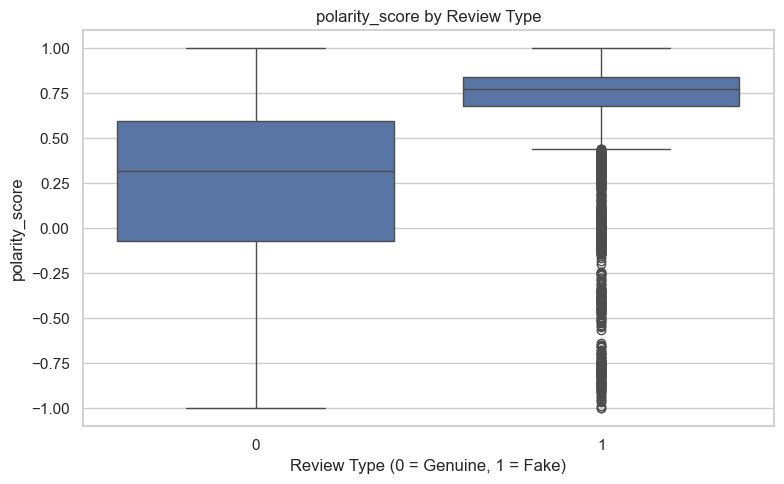

In [15]:
plot_box_by_target(df, "polarity_score")

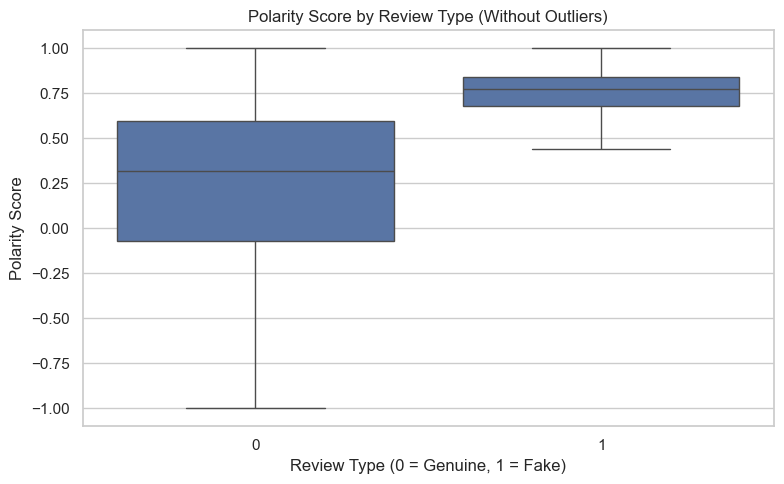

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='is_fake_review', y='polarity_score', showfliers=False)

plt.title("Polarity Score by Review Type (Without Outliers)")
plt.xlabel("Review Type (0 = Genuine, 1 = Fake)")
plt.ylabel("Polarity Score")

plt.tight_layout()
plt.savefig("outputs/polarity_score_boxplot_clean.png", dpi=300)
plt.show()

# 13. Plot 6: Subjectivity score

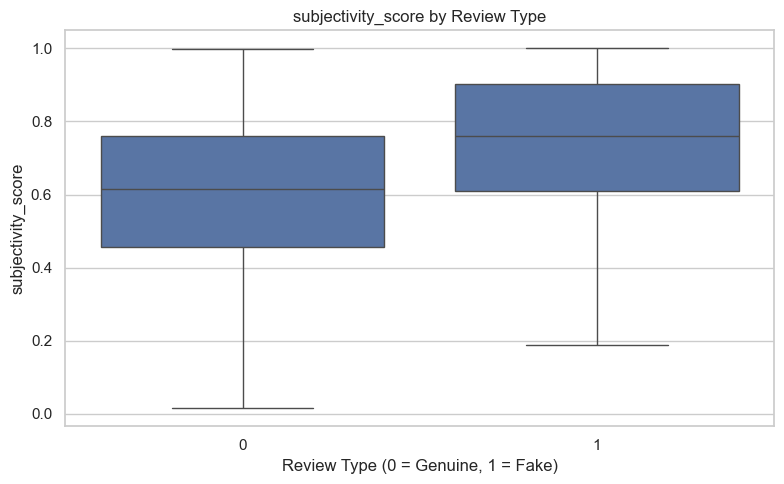

In [17]:
plot_box_by_target(df, "subjectivity_score")

# 14. Plot 7: Readability score

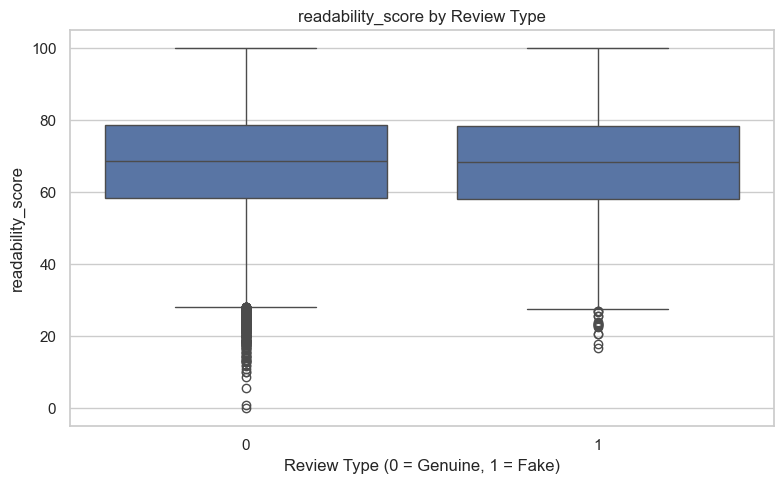

In [18]:
plot_box_by_target(df, "readability_score")

# 15. Plot 8: Exclamation marks

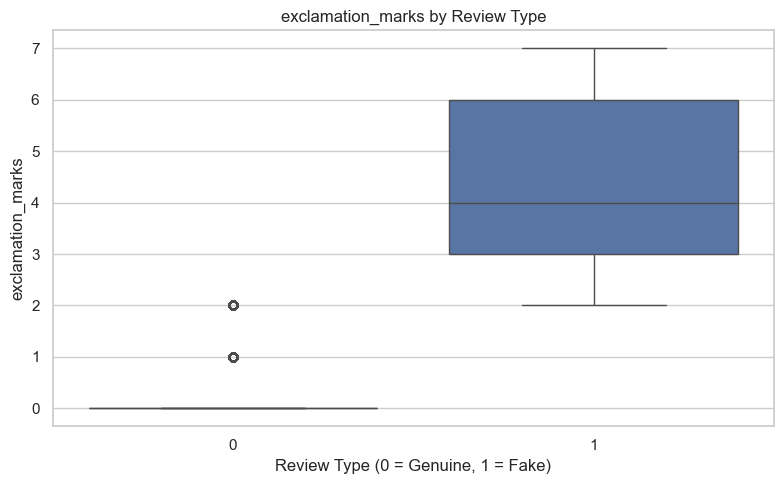

In [21]:
plot_box_by_target(df, "exclamation_marks")

# 16. Plot 9: All caps ratio

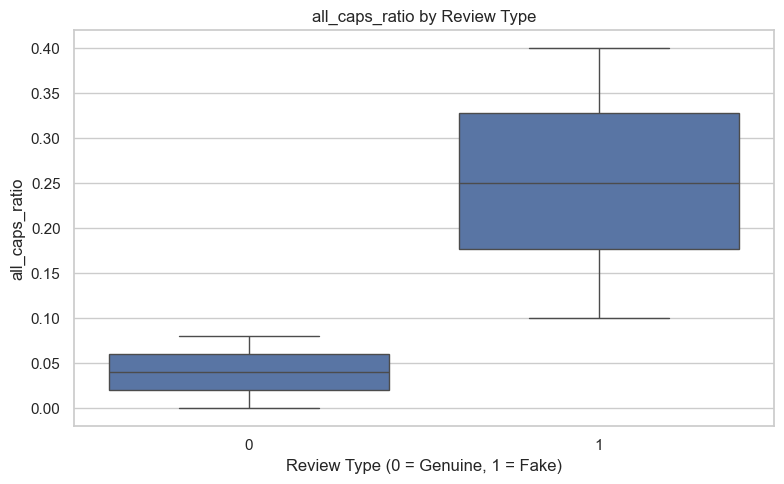

In [22]:
plot_box_by_target(df, "all_caps_ratio")

# 17. Numeric summary table

In [24]:
numeric_features = [
    "review_length_words",
    "helpful_ratio",
    "sentiment_score",
    "polarity_score",
    "subjectivity_score",
    "readability_score",
    "exclamation_marks",
    "all_caps_ratio"
]

numeric_summary = df.groupby("is_fake_review")[numeric_features].mean().T
numeric_summary.columns = ["genuine_mean", "fake_mean"]
numeric_summary["difference_fake_minus_genuine"] = numeric_summary["fake_mean"] - numeric_summary["genuine_mean"]

numeric_summary.round(3)

,genuine_mean,fake_mean,difference_fake_minus_genuine
review_length_words,67.448,75.565,8.116
helpful_ratio,0.803,0.794,-0.009
sentiment_score,0.243,0.798,0.555
polarity_score,0.200,0.663,0.463
subjectivity_score,0.601,0.743,0.142
readability_score,68.525,68.208,-0.317
exclamation_marks,0.250,4.508,4.258
all_caps_ratio,0.040,0.251,0.211


# 18. Helper function for categorical countplots

In [25]:
def plot_count_by_target(data, feature, target="is_fake_review", rotation=0, save=True):
    plt.figure(figsize=(8, 5))
    sns.countplot(data=data, x=feature, hue=target)
    plt.title(f"{feature} by Review Type")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    if save:
        plt.savefig(f"outputs/{feature}_countplot.png", dpi=300)
    plt.show()

# 19. Plot 10: Verified purchase

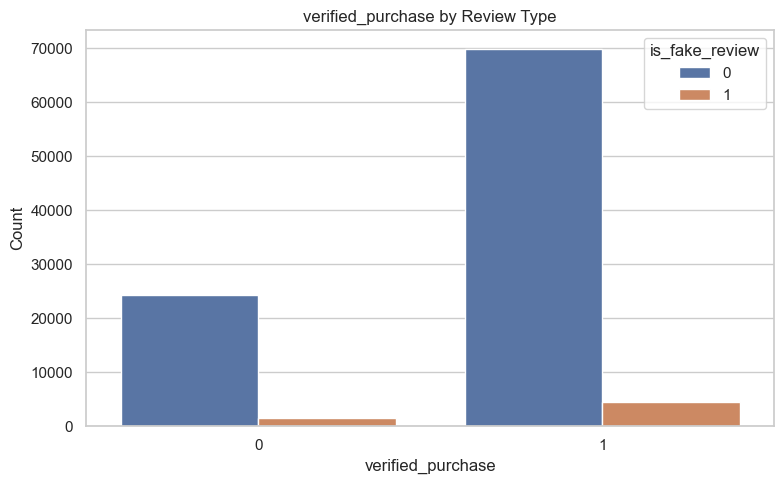

In [26]:
plot_count_by_target(df, "verified_purchase")

# 20. Plot 11: Sentiment label

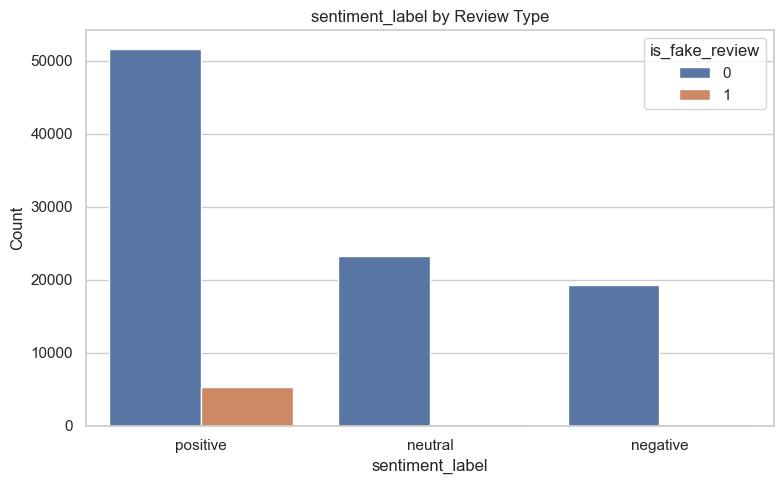

In [27]:
plot_count_by_target(df, "sentiment_label")

# 21. Plot 12: Emotion

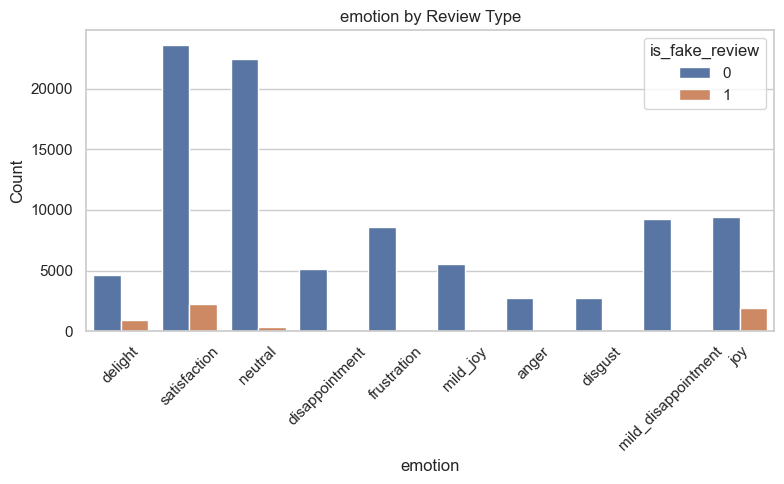

In [28]:
plot_count_by_target(df, "emotion", rotation=45)

# 22. Plot 13: Is sarcastic

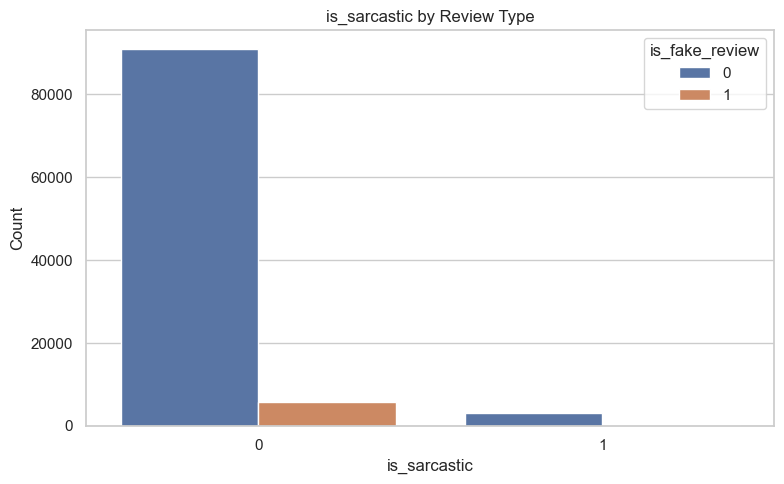

In [29]:
plot_count_by_target(df, "is_sarcastic")

# 23. Plot 14: Is top reviewer

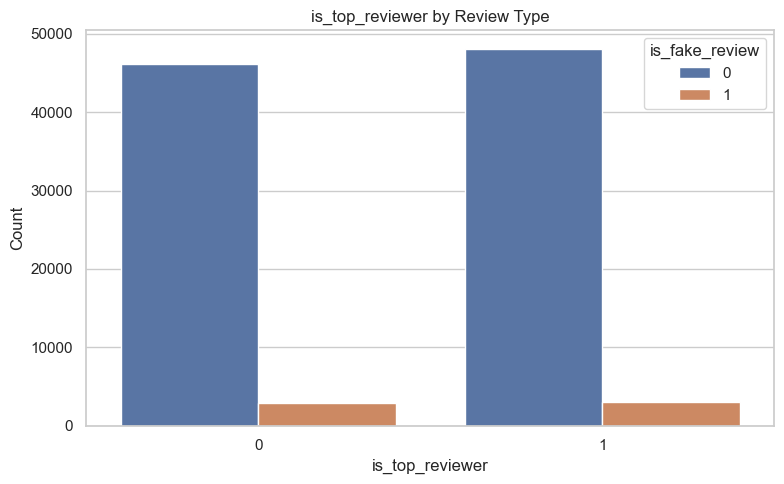

In [30]:
plot_count_by_target(df, "is_top_reviewer")

# 24. Plot 15: Category

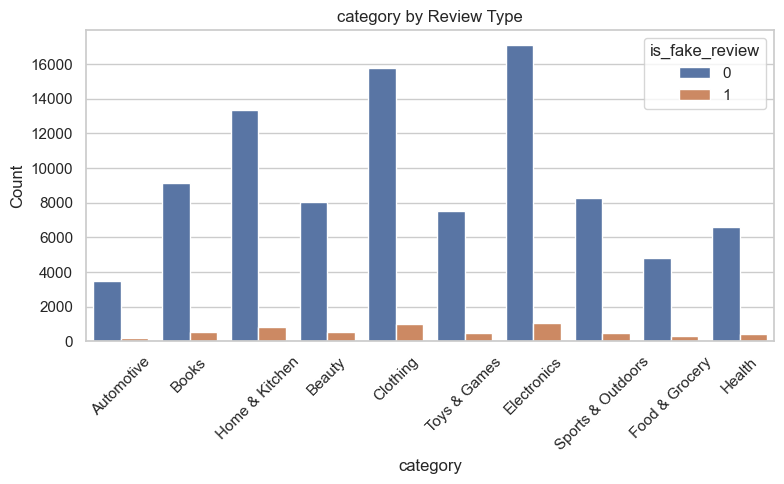

In [31]:
plot_count_by_target(df, "category", rotation=45)

# 25. Fake rate by verified purchase

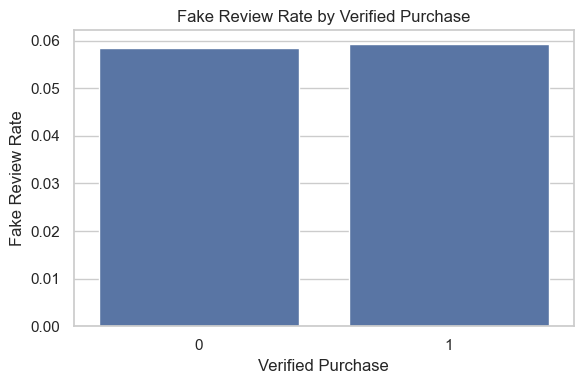

,verified_purchase,is_fake_review
0,0,0.058409
1,1,0.059206


In [32]:
verified_fake_rate = df.groupby("verified_purchase")["is_fake_review"].mean().reset_index()

plt.figure(figsize=(6, 4))
sns.barplot(data=verified_fake_rate, x="verified_purchase", y="is_fake_review")
plt.title("Fake Review Rate by Verified Purchase")
plt.xlabel("Verified Purchase")
plt.ylabel("Fake Review Rate")
plt.tight_layout()
plt.savefig("outputs/verified_purchase_fake_rate.png", dpi=300)
plt.show()

verified_fake_rate

# 26. Fake rate by category

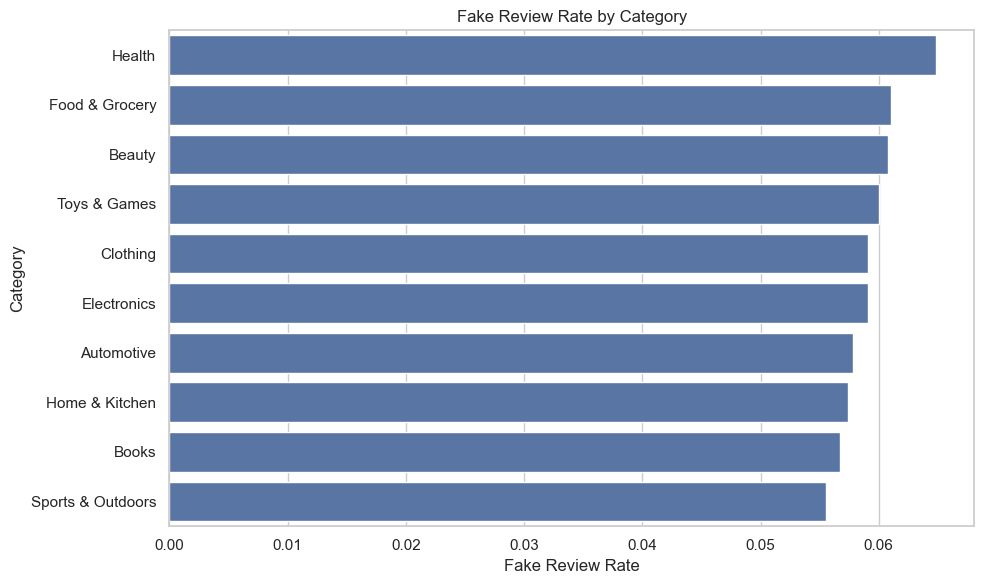

,category,is_fake_review
0,Health,0.064817
1,Food & Grocery,0.061016
2,Beauty,0.060747
3,Toys & Games,0.060060
4,Clothing,0.059132
5,Electronics,0.059092
6,Automotive,0.057858
7,Home & Kitchen,0.057403
8,Books,0.056744
9,Sports & Outdoors,0.055575


In [33]:
category_fake_rate = df.groupby("category")["is_fake_review"].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=category_fake_rate, x="is_fake_review", y="category")
plt.title("Fake Review Rate by Category")
plt.xlabel("Fake Review Rate")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("outputs/category_fake_rate.png", dpi=300)
plt.show()

category_fake_rate.head(10)

# 27. Fake rate by emotion

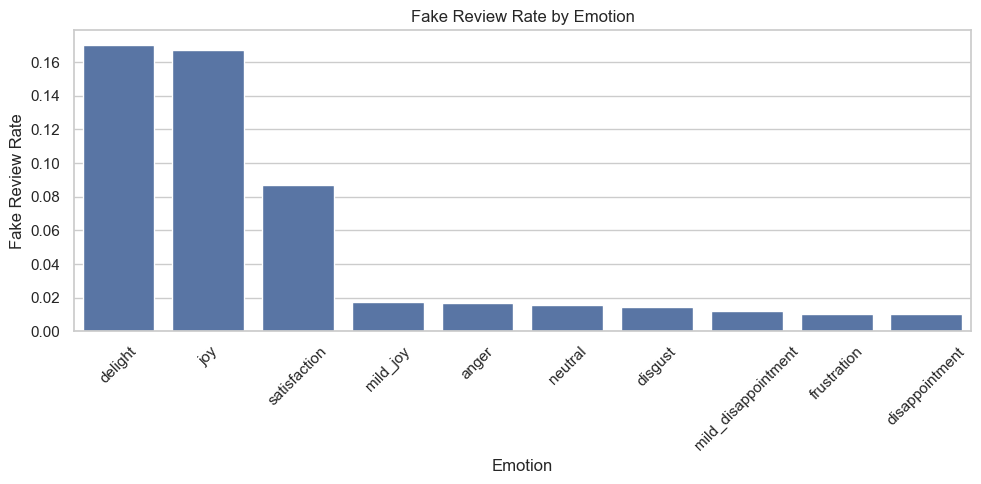

,emotion,is_fake_review
0,delight,0.170262
1,joy,0.167020
2,satisfaction,0.087229
3,mild_joy,0.017348
4,anger,0.016906
5,neutral,0.015598
6,disgust,0.014759
7,mild_disappointment,0.012215
8,frustration,0.010460
9,disappointment,0.010347


In [34]:
emotion_fake_rate = df.groupby("emotion")["is_fake_review"].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=emotion_fake_rate, x="emotion", y="is_fake_review")
plt.title("Fake Review Rate by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Fake Review Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/emotion_fake_rate.png", dpi=300)
plt.show()

emotion_fake_rate

# 28. Context feature boxplots

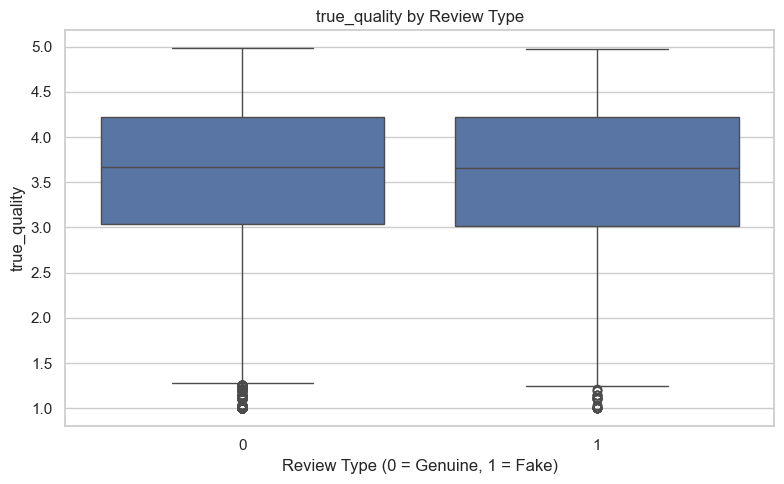

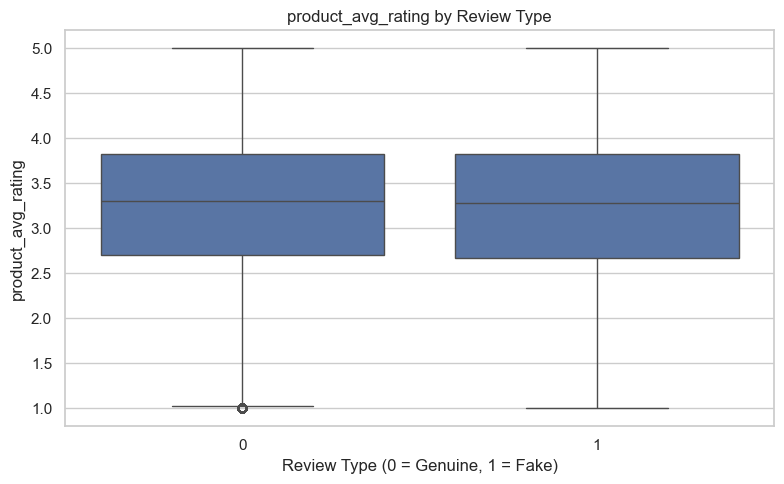

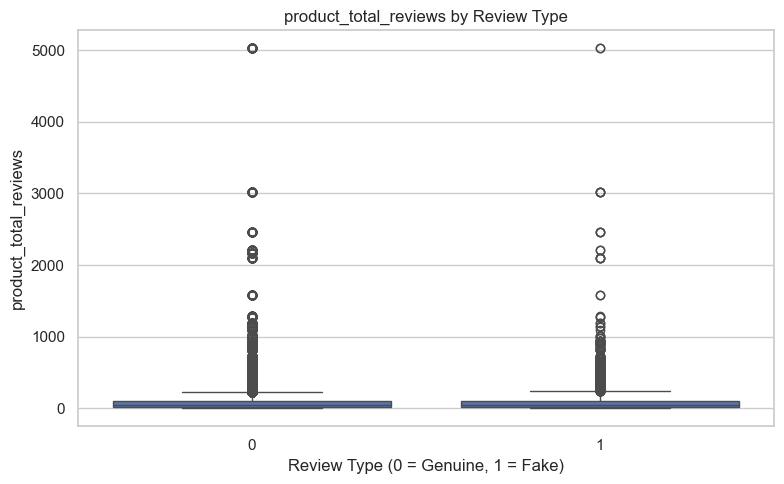

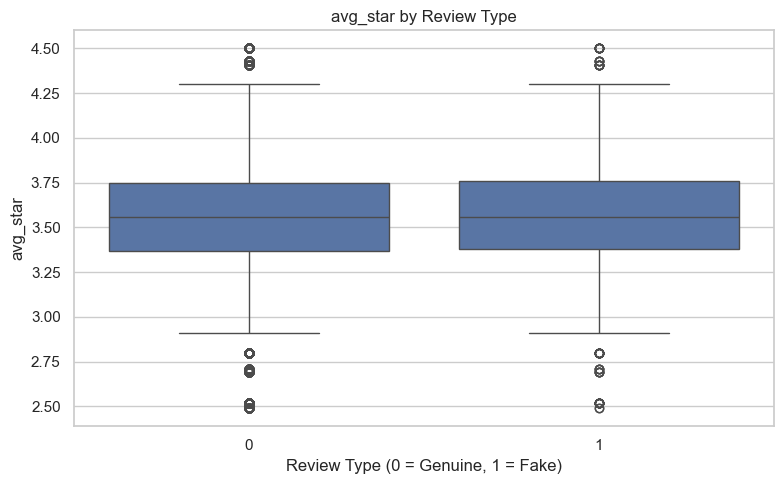

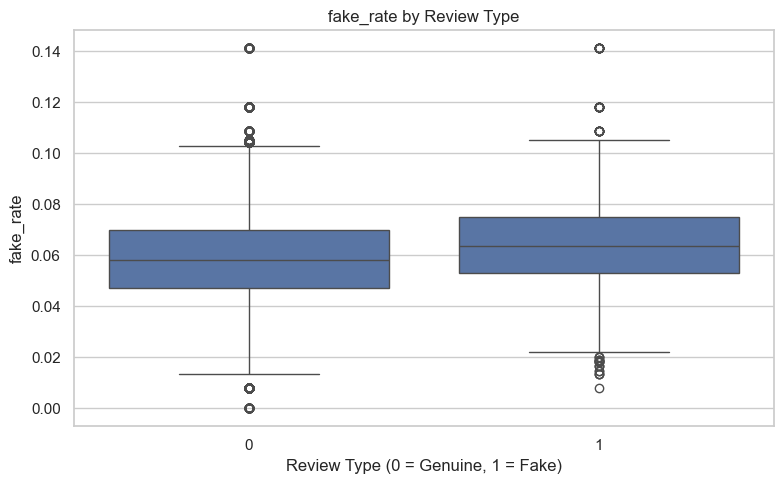

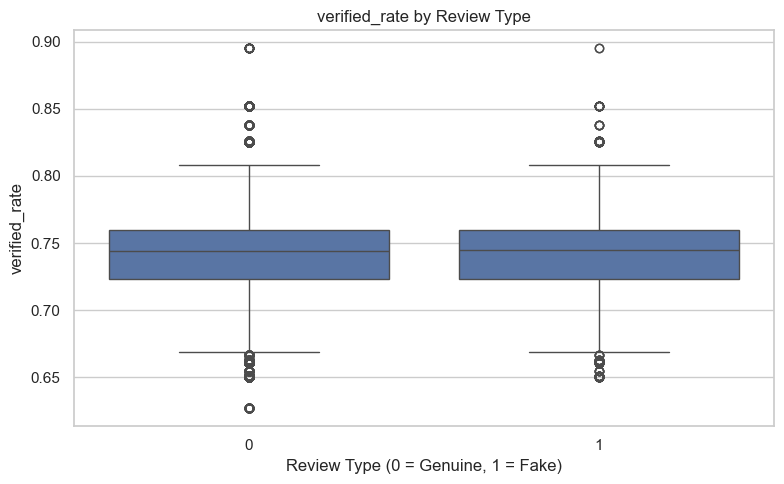

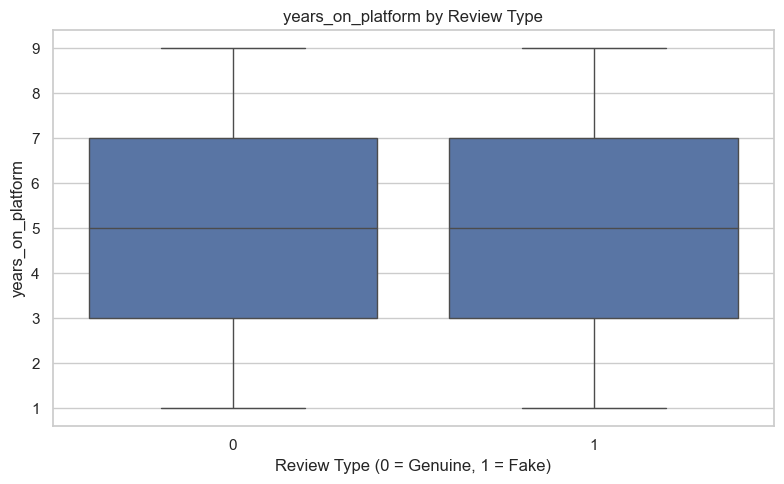

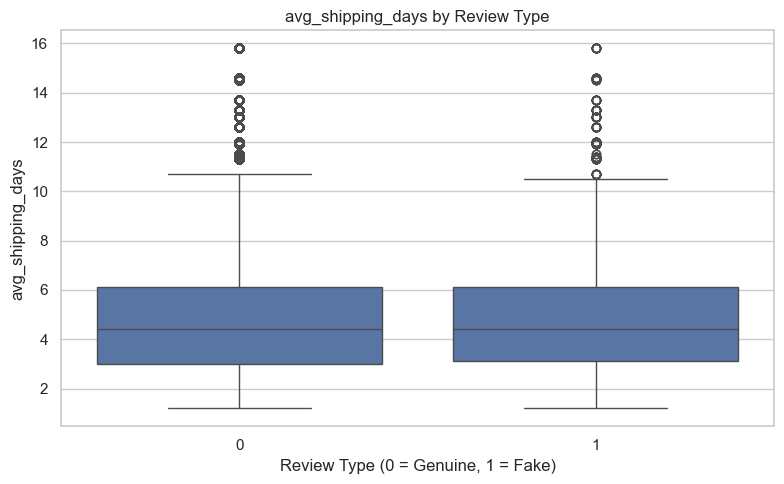

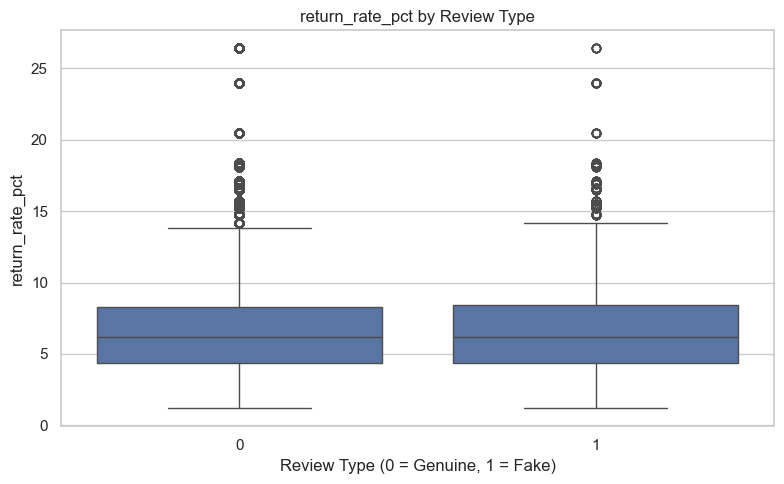

In [35]:
context_features = [
    "true_quality",
    "product_avg_rating",
    "product_total_reviews",
    "avg_star",
    "fake_rate",
    "verified_rate",
    "years_on_platform",
    "avg_shipping_days",
    "return_rate_pct"
]

for col in context_features:
    if col in df.columns:
        plot_box_by_target(df, col)

# 29. Context summary table

In [36]:
available_context_features = [col for col in context_features if col in df.columns]

context_summary = df.groupby("is_fake_review")[available_context_features].mean().T
context_summary.columns = ["genuine_mean", "fake_mean"]
context_summary["difference_fake_minus_genuine"] = context_summary["fake_mean"] - context_summary["genuine_mean"]

context_summary.round(3)

,genuine_mean,fake_mean,difference_fake_minus_genuine
true_quality,3.579,3.571,-0.008
product_avg_rating,3.223,3.209,-0.014
product_total_reviews,99.157,99.906,0.749
avg_star,3.565,3.577,0.012
fake_rate,0.059,0.064,0.005
verified_rate,0.742,0.742,0.000
years_on_platform,4.861,4.886,0.025
avg_shipping_days,4.871,4.843,-0.028
return_rate_pct,6.930,6.971,0.041


# 30. Correlation heatmap

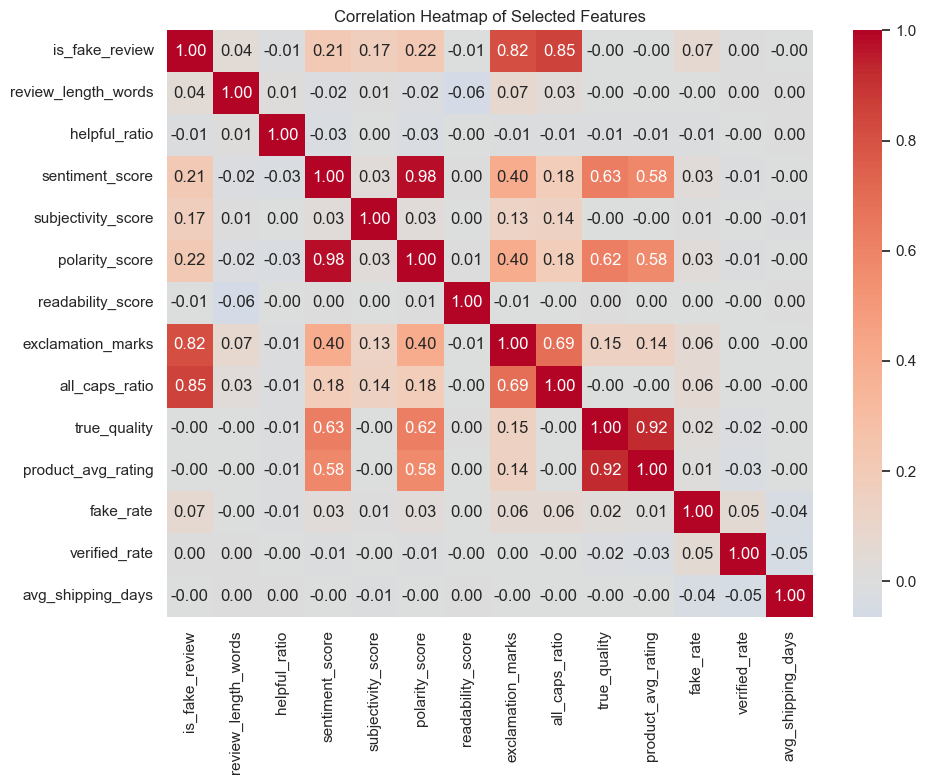

In [37]:
corr_features = [
    "is_fake_review",
    "review_length_words",
    "helpful_ratio",
    "sentiment_score",
    "subjectivity_score",
    "polarity_score",
    "readability_score",
    "exclamation_marks",
    "all_caps_ratio",
    "true_quality",
    "product_avg_rating",
    "fake_rate",
    "verified_rate",
    "avg_shipping_days"
]

available_corr_features = [col for col in corr_features if col in df.columns]

corr_matrix = df[available_corr_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Selected Features")
plt.tight_layout()
plt.savefig("outputs/correlation_heatmap.png", dpi=300)
plt.show()

# 31. Quick summary statistics by target

In [38]:
summary_by_target = df.groupby("is_fake_review").agg({
    "review_length_words": ["mean", "median"],
    "helpful_ratio": ["mean", "median"],
    "sentiment_score": ["mean", "median"],
    "polarity_score": ["mean", "median"],
    "subjectivity_score": ["mean", "median"],
    "verified_purchase": ["mean"],
    "is_sarcastic": ["mean"]
}).round(3)

summary_by_target

review_length_words        helpful_ratio        sentiment_score        polarity_score        subjectivity_score        verified_purchase is_sarcastic
                              mean median          mean median            mean median           mean median               mean median              mean         mean
is_fake_review                                                                                                                                                      
0                           67.448   55.0         0.803  0.897           0.243  0.402          0.200  0.321              0.601  0.616             0.742        0.034
1                           75.565   63.0         0.794  0.889           0.798  0.969          0.663  0.776              0.743  0.760             0.744        0.022

# 32. Export summary tables

In [39]:
numeric_summary.round(3).to_csv("outputs/numeric_summary.csv")
context_summary.round(3).to_csv("outputs/context_summary.csv")
summary_by_target.to_csv("outputs/summary_by_target.csv")

print("EDA outputs saved successfully.")

EDA outputs saved successfully.


# 33. Findings summary

## EDA Findings Summary

This exploratory data analysis identified several important patterns that support the fake review detection task.

### Key findings

1. The dataset is highly imbalanced, with fake reviews representing only a small proportion of all reviews. This suggests that later models should prioritise recall, precision and F1-score instead of accuracy alone.

2. Strong linguistic style differences were observed between fake and genuine reviews:
   - fake reviews contain more capitalised words,
   - fake reviews use more exclamation marks,
   - fake reviews tend to show stronger positive sentiment.

3. Emotion-related features also provide meaningful signals. Fake reviews are more likely to express exaggerated positive emotions such as delight and satisfaction.

4. Contextual variables such as verified purchase and seller fake review history show additional predictive value.

5. Correlation analysis indicates strong multicollinearity among some features, particularly sentiment_score and polarity_score, as well as true_quality and product_avg_rating.

### Implications for Phase 3

These findings support the use of a hybrid fake review detection pipeline that combines:
- metadata features,
- linguistic sentiment features,
- contextual seller/product features.

Potential leakage features such as fake_confidence_score and sent_is_fake_review will be excluded before model training.